In [2]:
import pandas as pd

df = pd.read_csv("Telco-Customer-Churn.csv")

print("Kích thước dữ liệu:", df.shape)
print("\nTên các cột:")
print(df.columns.tolist())

print("\nNhãn Churn:")
print(df["Churn"].value_counts(dropna=False))

print("\nTỷ lệ nhãn (%):")
print((df["Churn"].value_counts(normalize=True, dropna=False) * 100).round(2))

Kích thước dữ liệu: (7043, 21)

Tên các cột:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Nhãn Churn:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Tỷ lệ nhãn (%):
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


In [4]:
import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import train_test_split

# 1. Đọc dữ liệu
df = pd.read_csv('Telco-Customer-Churn.csv')

# 2. Kiểm tra danh sách 19 đặc trưng thô ban đầu
raw_features = [col for col in df.columns if col not in ['customerID', 'Churn']]
print(f'1. Số lượng đặc trưng thô: {len(raw_features)}')
print('Danh sách cột:', raw_features)

# 3. Kiểm tra phân bố nhãn Churn thực tế
print('\n2. Phân bố nhãn Churn:')
print(df['Churn'].value_counts())
print(df['Churn'].value_counts(normalize=True) * 100)

# 4. Tách X, y và chia tập Train - Test phân tầng (80/20)
X = df[raw_features]
y = df['Churn'].map({'No': 0, 'Yes': 1})
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 5. Huấn luyện DummyClassifier để lấy con số Baseline thực tế
dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(X_train, y_train)
y_pred = dummy.predict(X_test)
y_proba = dummy.predict_proba(X_test)[:, 1]

print('\n3. Kết quả Baseline thực nghiệm:')
print(f'Recall (Lớp 1):    {recall_score(y_test, y_pred, zero_division=0):.4f}')
print(
    f'Precision (Lớp 1): {precision_score(y_test, y_pred, zero_division=0):.4f}'
)
print(f'F1-Score (Lớp 1):  {f1_score(y_test, y_pred, zero_division=0):.4f}')
print(f'ROC-AUC:           {roc_auc_score(y_test, y_proba):.4f}')

1. Số lượng đặc trưng thô: 19
Danh sách cột: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']

2. Phân bố nhãn Churn:
Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

3. Kết quả Baseline thực nghiệm:
Recall (Lớp 1):    0.0000
Precision (Lớp 1): 0.0000
F1-Score (Lớp 1):  0.0000
ROC-AUC:           0.5000


In [5]:
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency

# 1. Đọc dữ liệu và xử lý tạm thời cột TotalCharges để tính toán thống kê
df = pd.read_csv('Telco-Customer-Churn.csv')
df['TotalCharges'] = df['TotalCharges'].replace(' ', np.nan)
df['TotalCharges'] = df['TotalCharges'].fillna(0.0).astype(float)

print('=' * 70)
print('1. BẢNG THỐNG KÊ MÔ TẢ CÁC BIẾN ĐỊNH LƯỢNG (TIÊU CHÍ 4)')
print('=' * 70)
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
desc_stats = df[num_cols].describe().T
desc_stats['skewness'] = df[num_cols].skew()
print(
    desc_stats[
        ['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max', 'skewness']
    ]
)

print('\n' + '=' * 70)
print('2. TỶ LỆ CHURN THEO LOẠI HỢP ĐỒNG (CONTRACT)')
print('=' * 70)
contract_churn = (
    pd.crosstab(df['Contract'], df['Churn'], normalize='index') * 100
)
print(contract_churn)

print('\n' + '=' * 70)
print('3. TỶ LỆ CHURN THEO DỊCH VỤ INTERNET (INTERNETSERVICE)')
print('=' * 70)
internet_churn = (
    pd.crosstab(df['InternetService'], df['Churn'], normalize='index') * 100
)
print(internet_churn)

print('\n' + '=' * 70)
print('4. TỶ LỆ CHURN PHÂN LỚP CHÉO: INTERNETSERVICE x TECHSUPPORT')
print('=' * 70)
fiber_tech = (
    pd.crosstab(
        [df['InternetService'], df['TechSupport']],
        df['Churn'],
        normalize='index',
    )
    * 100
)
print(fiber_tech)

print('\n' + '=' * 70)
print('5. MA TRẬN TƯƠNG QUAN PEARSON GIỮA CÁC BIẾN SỐ')
print('=' * 70)
print(df[num_cols].corr(method='pearson'))

print('\n' + '=' * 70)
print('6. KIỂM ĐỊNH CHI BÌNH PHƯƠNG (CHI-SQUARE TEST)')
print('=' * 70)
for cat_col in ['Contract', 'InternetService']:
    contingency_table = pd.crosstab(df[cat_col], df['Churn'])
    chi2, p, dof, _ = chi2_contingency(contingency_table)
    print(f'Kiểm định {cat_col} vs Churn: Chi2 = {chi2:.2f}, p-value = {p:.4e}')

1. BẢNG THỐNG KÊ MÔ TẢ CÁC BIẾN ĐỊNH LƯỢNG (TIÊU CHÍ 4)
                 count         mean          std    min     25%      50%  \
tenure          7043.0    32.371149    24.559481   0.00    9.00    29.00   
MonthlyCharges  7043.0    64.761692    30.090047  18.25   35.50    70.35   
TotalCharges    7043.0  2279.734304  2266.794470   0.00  398.55  1394.55   

                    75%      max  skewness  
tenure            55.00    72.00  0.239540  
MonthlyCharges    89.85   118.75 -0.220524  
TotalCharges    3786.60  8684.80  0.963235  

2. TỶ LỆ CHURN THEO LOẠI HỢP ĐỒNG (CONTRACT)
Churn                  No        Yes
Contract                            
Month-to-month  57.290323  42.709677
One year        88.730482  11.269518
Two year        97.168142   2.831858

3. TỶ LỆ CHURN THEO DỊCH VỤ INTERNET (INTERNETSERVICE)
Churn                   No        Yes
InternetService                      
DSL              81.040892  18.959108
Fiber optic      58.107235  41.892765
No               92.

C:\Users\MY PC\AppData\Local\Temp\ipykernel_11764\413756389.py:8: Pandas4Warning: 'float' is not supported as a fill value for str dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  df['TotalCharges'] = df['TotalCharges'].fillna(0.0).astype(float)


C:\Users\MY PC\AppData\Local\Temp\ipykernel_11764\471525278.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


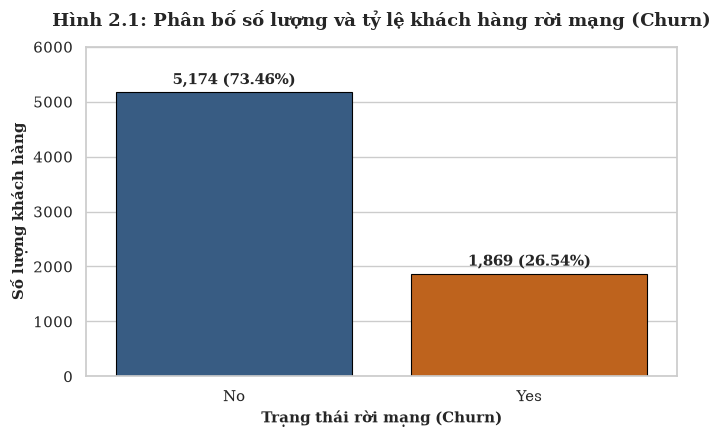

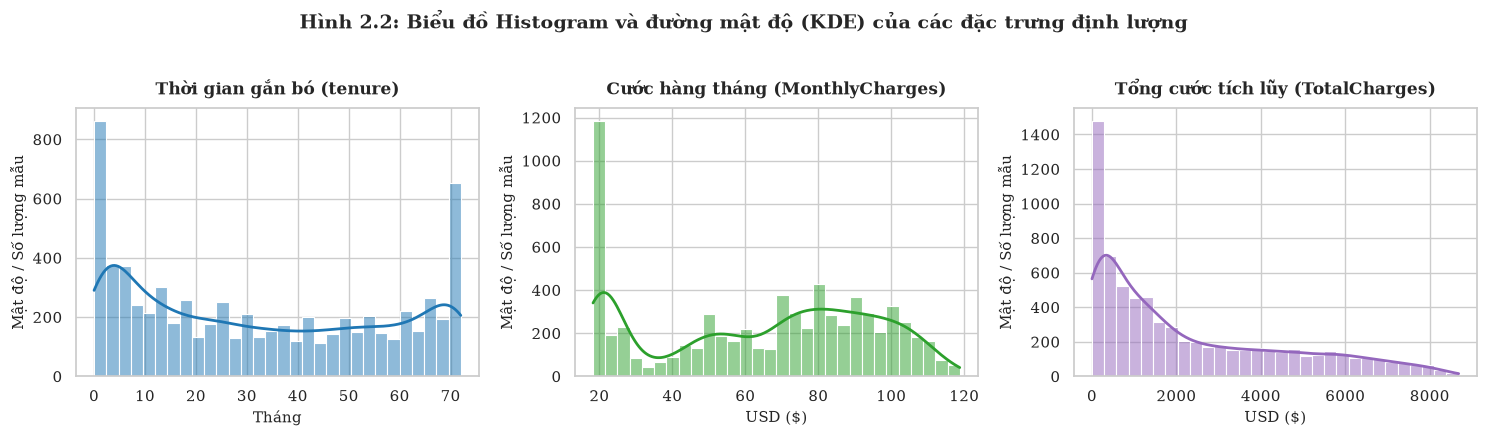

Đã xuất thành công 2 tệp ảnh:
1. hinh_2_1_phan_bo_churn.png
2. hinh_2_2_phan_bo_bien_so.png


In [7]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Thiết lập phong cách hiển thị biểu đồ
sns.set_theme(style='whitegrid')
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.size'] = 11

# 1. Đọc và tiền xử lý nhanh dữ liệu để vẽ
df = pd.read_csv('Telco-Customer-Churn.csv')
df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'].replace(' ', np.nan)
).fillna(0.0)

# ==============================================================================
# HÌNH 2.1: BIỂU ĐỒ PHÂN BỐ BIẾN MỤC TIÊU CHURN
# ==============================================================================
plt.figure(figsize=(7, 4.5))

churn_counts = df['Churn'].value_counts()
churn_pcts = df['Churn'].value_counts(normalize=True) * 100
colors = ['#2b5c8f', '#d95f02']  # Xanh navy (No) và Cam đậm (Yes)

ax = sns.barplot(
    x=churn_counts.index,
    y=churn_counts.values,
    palette=colors,
    edgecolor='black',
    linewidth=0.8,
)

# Hiển thị số lượng và tỷ lệ % trên đầu từng cột
for i, count in enumerate(churn_counts.values):
  pct = churn_pcts.values[i]
  ax.text(
      i,
      count + 80,
      f'{count:,} ({pct:.2f}%)',
      ha='center',
      va='bottom',
      fontweight='bold',
      fontsize=11,
  )

plt.title(
    'Hình 2.1: Phân bố số lượng và tỷ lệ khách hàng rời mạng (Churn)',
    fontsize=13,
    fontweight='bold',
    pad=15,
)
plt.xlabel('Trạng thái rời mạng (Churn)', fontsize=11, fontweight='bold')
plt.ylabel('Số lượng khách hàng', fontsize=11, fontweight='bold')
plt.ylim(0, 6000)
plt.tight_layout()

# Lưu hình 2.1
plt.savefig('hinh_2_1_phan_bo_churn.png', dpi=300)
plt.show()

# ==============================================================================
# HÌNH 2.2: BIỂU ĐỒ HISTOGRAM & KDE CỦA TENURE, MONTHLYCHARGES VÀ TOTALCHARGES
# ==============================================================================
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

features = ['tenure', 'MonthlyCharges', 'TotalCharges']
titles = [
    'Thời gian gắn bó (tenure)',
    'Cước hàng tháng (MonthlyCharges)',
    'Tổng cước tích lũy (TotalCharges)',
]
x_labels = ['Tháng', 'USD ($)', 'USD ($)']
palette_colors = ['#1f77b4', '#2ca02c', '#9467bd']

for i, col in enumerate(features):
  sns.histplot(
      df[col],
      kde=True,
      ax=axes[i],
      color=palette_colors[i],
      bins=30,
      edgecolor='white',
      linewidth=0.8,
      line_kws={'linewidth': 2},
  )
  axes[i].set_title(titles[i], fontsize=12, fontweight='bold', pad=10)
  axes[i].set_xlabel(x_labels[i], fontsize=11)
  axes[i].set_ylabel('Mật độ / Số lượng mẫu', fontsize=11)

plt.suptitle(
    'Hình 2.2: Biểu đồ Histogram và đường mật độ (KDE) của các đặc trưng định lượng',
    fontsize=14,
    fontweight='bold',
    y=1.03,
)
plt.tight_layout()

# Lưu hình 2.2
plt.savefig('hinh_2_2_phan_bo_bien_so.png', dpi=300)
plt.show()

print('Đã xuất thành công 2 tệp ảnh:')
print('1. hinh_2_1_phan_bo_churn.png')
print('2. hinh_2_2_phan_bo_bien_so.png')

In [1]:
import numpy as np
import pandas as pd

# 1. Đọc dữ liệu gốc
df = pd.read_csv('Telco-Customer-Churn.csv')

print('=' * 70)
print('1. KIỂM TRA 11 GIÁ TRỊ THIẾU Ở TOTALCHARGES')
print('=' * 70)
missing_mask = df['TotalCharges'].str.strip() == ''
missing_count = missing_mask.sum()
print(f'Số lượng ô khoảng trắng ở TotalCharges: {missing_count}')
print(
    f'Giá trị tenure tương ứng của các dòng này: {df.loc[missing_mask, "tenure"].tolist()}'
)

print('\n' + '=' * 70)
print('2. KIỂM TRA TRÙNG LẶP VÀ ĐỊNH DANH')
print('=' * 70)
dup_count = df.duplicated().sum()
id_unique = df['customerID'].nunique()
print(f'Số bản ghi trùng lặp hoàn toàn: {dup_count}')
print(
    f'Số mã customerID duy nhất: {id_unique} / Tổng số dòng: {len(df)}'
)

print('\n' + '=' * 70)
print('3. KIỂM TRA NGOẠI LAI THỐNG KÊ BẰNG QUY TẮC IQR')
print('=' * 70)
# Ép kiểu TotalCharges để tính toán
tc_numeric = pd.to_numeric(
    df['TotalCharges'].replace(' ', np.nan)
).fillna(0.0)
temp_df = df.copy()
temp_df['TotalCharges'] = tc_numeric

for col in ['tenure', 'MonthlyCharges', 'TotalCharges']:
  q1 = temp_df[col].quantile(0.25)
  q3 = temp_df[col].quantile(0.75)
  iqr = q3 - q1
  lower_bound = q1 - 1.5 * iqr
  upper_bound = q3 + 1.5 * iqr
  outliers = temp_df[
      (temp_df[col] < lower_bound) | (temp_df[col] > upper_bound)
  ]
  print(
      f'Cột {col:15s}: Q1={q1:.2f}, Q3={q3:.2f}, IQR={iqr:.2f} | Ngưỡng: [{lower_bound:.2f}, {upper_bound:.2f}] -> Số ngoại lai IQR: {len(outliers)}'
  )

1. KIỂM TRA 11 GIÁ TRỊ THIẾU Ở TOTALCHARGES
Số lượng ô khoảng trắng ở TotalCharges: 11
Giá trị tenure tương ứng của các dòng này: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

2. KIỂM TRA TRÙNG LẶP VÀ ĐỊNH DANH
Số bản ghi trùng lặp hoàn toàn: 0
Số mã customerID duy nhất: 7043 / Tổng số dòng: 7043

3. KIỂM TRA NGOẠI LAI THỐNG KÊ BẰNG QUY TẮC IQR
Cột tenure         : Q1=9.00, Q3=55.00, IQR=46.00 | Ngưỡng: [-60.00, 124.00] -> Số ngoại lai IQR: 0
Cột MonthlyCharges : Q1=35.50, Q3=89.85, IQR=54.35 | Ngưỡng: [-46.02, 171.38] -> Số ngoại lai IQR: 0
Cột TotalCharges   : Q1=398.55, Q3=3786.60, IQR=3388.05 | Ngưỡng: [-4683.52, 8868.67] -> Số ngoại lai IQR: 0


In [3]:
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# 1. Đọc dữ liệu và xử lý giá trị trống
df = pd.read_csv('Telco-Customer-Churn.csv')
df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'].replace(' ', np.nan)
).fillna(0.0)

# 2. Tách không gian đặc trưng X (19 cột thô) và nhãn mục tiêu y
X = df.drop(columns=['customerID', 'Churn'])
y = df['Churn'].map({'No': 0, 'Yes': 1})

# 3. Phân chia Train - Test phân tầng (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print('=' * 70)
print('1. KÍCH THƯỚC PHÂN CHIA TẬP DỮ LIỆU (TRAIN - TEST)')
print('=' * 70)
print(f'Tập Train: {X_train.shape[0]} dòng ({X_train.shape[0]/len(df)*100:.1f}%)')
print(
    f'  - Lớp 0 (No): {(y_train == 0).sum()} mẫu ({(y_train == 0).mean()*100:.2f}%)'
)
print(
    f'  - Lớp 1 (Yes): {(y_train == 1).sum()} mẫu ({(y_train == 1).mean()*100:.2f}%)'
)

print(f'\nTập Test:  {X_test.shape[0]} dòng ({X_test.shape[0]/len(df)*100:.1f}%)')
print(
    f'  - Lớp 0 (No): {(y_test == 0).sum()} mẫu ({(y_test == 0).mean()*100:.2f}%)'
)
print(
    f'  - Lớp 1 (Yes): {(y_test == 1).sum()} mẫu ({(y_test == 1).mean()*100:.2f}%)'
)

# 4. Thiết lập ColumnTransformer
num_features = ['tenure', 'MonthlyCharges', 'TotalCharges']
bin_features = [
    'gender',
    'Partner',
    'Dependents',
    'PhoneService',
    'PaperlessBilling',
]
cat_features = [
    'MultipleLines',
    'InternetService',
    'OnlineSecurity',
    'OnlineBackup',
    'DeviceProtection',
    'TechSupport',
    'StreamingTV',
    'StreamingMovies',
    'Contract',
    'PaymentMethod',
]

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_features),
        (
            'bin',
            OneHotEncoder(drop='if_binary', handle_unknown='ignore'),
            bin_features,
        ),
        (
            'cat',
            OneHotEncoder(drop='first', handle_unknown='ignore'),
            cat_features,
        ),
    ],
    remainder='passthrough',  # Giữ nguyên cột SeniorCitizen (0/1)
)

# 5. Fit trên Train và Transform trên Test
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print('\n' + '=' * 70)
print('2. SỐ CHIỀU THỰC TẾ SAU TIỀN XỬ LÝ (COLUMNTANSFORMER)')
print('=' * 70)
print(f'Số chiều X_train_processed: {X_train_processed.shape}')
print(f'Số chiều X_test_processed:  {X_test_processed.shape}')
print(f'Số cột đặc trưng thực tế:    {X_train_processed.shape[1]} cột')

# 6. Danh sách tên các cột mới sau biến đổi
feature_names = preprocessor.get_feature_names_out()
print(f'\n3. Danh sách {len(feature_names)} cột đặc trưng sau biến đổi:')
for idx, name in enumerate(feature_names, 1):
  print(f'  {idx:2d}. {name}')

1. KÍCH THƯỚC PHÂN CHIA TẬP DỮ LIỆU (TRAIN - TEST)
Tập Train: 5634 dòng (80.0%)
  - Lớp 0 (No): 4139 mẫu (73.46%)
  - Lớp 1 (Yes): 1495 mẫu (26.54%)

Tập Test:  1409 dòng (20.0%)
  - Lớp 0 (No): 1035 mẫu (73.46%)
  - Lớp 1 (Yes): 374 mẫu (26.54%)

2. SỐ CHIỀU THỰC TẾ SAU TIỀN XỬ LÝ (COLUMNTANSFORMER)
Số chiều X_train_processed: (5634, 30)
Số chiều X_test_processed:  (1409, 30)
Số cột đặc trưng thực tế:    30 cột

3. Danh sách 30 cột đặc trưng sau biến đổi:
   1. num__tenure
   2. num__MonthlyCharges
   3. num__TotalCharges
   4. bin__gender_Male
   5. bin__Partner_Yes
   6. bin__Dependents_Yes
   7. bin__PhoneService_Yes
   8. bin__PaperlessBilling_Yes
   9. cat__MultipleLines_No phone service
  10. cat__MultipleLines_Yes
  11. cat__InternetService_Fiber optic
  12. cat__InternetService_No
  13. cat__OnlineSecurity_No internet service
  14. cat__OnlineSecurity_Yes
  15. cat__OnlineBackup_No internet service
  16. cat__OnlineBackup_Yes
  17. cat__DeviceProtection_No internet service
  1

In [ ]:


import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Thiết lập font chữ và phong cách hiển thị học thuật
plt.rcParams['font.sans-serif'] = ['Segoe UI', 'Arial', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
sns.set_theme(style='whitegrid', font='Segoe UI')

# 1. Đọc và tiền xử lý dữ liệu cơ sở
df = pd.read_csv('Telco-Customer-Churn.csv')
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'].replace(' ', np.nan)).fillna(0.0)

palette_churn = {'No': '#2b5c8f', 'Yes': '#d9534f'}  # Xanh dương (No) - Đỏ cam (Yes)

# ------------------------------------------------------------------------------
# HÌNH 2.3: TỶ LỆ RỜI MẠNG THEO LOẠI HỢP ĐỒNG VÀ DỊCH VỤ CÁP QUANG / HỖ TRỢ KỸ THUẬT
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), dpi=300)

# A. Tỷ lệ Churn theo Loại hợp đồng (Contract)
contract_churn = df.groupby('Contract')['Churn'].value_counts(normalize=True).mul(100).rename('Tỷ lệ (%)').reset_index()
order_contract = ['Month-to-month', 'One year', 'Two year']
rename_contract = {
    'Month-to-month': 'Từng tháng\n(Month-to-month)',
    'One year': '1 Năm\n(One year)',
    'Two year': '2 Năm\n(Two year)'
}
contract_churn['Contract_Label'] = contract_churn['Contract'].map(rename_contract)
order_labels = [rename_contract[k] for k in order_contract]

sns.barplot(
    data=contract_churn,
    x='Contract_Label',
    y='Tỷ lệ (%)',
    hue='Churn',
    palette=palette_churn,
    ax=axes[0],
    order=order_labels
)
axes[0].set_title('A. Tỷ lệ rời mạng theo Loại hợp đồng (Contract)\nChi2 = 1184.60, p < 0.001', fontsize=12, fontweight='bold', pad=12)
axes[0].set_xlabel('Loại hợp đồng', fontsize=11, fontweight='semibold')
axes[0].set_ylabel('Tỷ lệ phần trăm (%)', fontsize=11, fontweight='semibold')
axes[0].set_ylim(0, 110)
axes[0].legend(title='Rời mạng (Churn)', loc='upper right', frameon=True)

for p in axes[0].patches:
    height = p.get_height()
    if height > 0:
        axes[0].annotate(f'{height:.1f}%',
                         (p.get_x() + p.get_width() / 2., height + 2),
                         ha='center', va='bottom', fontsize=10, fontweight='bold',
                         color='#333333')

# B. Tỷ lệ Churn nhóm Cáp quang theo Hỗ trợ kỹ thuật
fiber_df = df[df['InternetService'] == 'Fiber optic'].copy()
fiber_tech = fiber_df.groupby('TechSupport')['Churn'].value_counts(normalize=True).mul(100).rename('Tỷ lệ (%)').reset_index()
rename_tech = {'No': 'Không có TechSupport\n(Rủi ro cao nhất)', 'Yes': 'Có TechSupport\n(Được hỗ trợ)'}
fiber_tech['Tech_Label'] = fiber_tech['TechSupport'].map(rename_tech)
order_tech = [rename_tech['No'], rename_tech['Yes']]

sns.barplot(
    data=fiber_tech,
    x='Tech_Label',
    y='Tỷ lệ (%)',
    hue='Churn',
    palette=palette_churn,
    ax=axes[1],
    order=order_tech
)
axes[1].set_title('B. Nhóm dùng Cáp quang (Fiber optic): Vai trò của TechSupport\nGiảm tỷ lệ rời mạng từ 49.4% xuống 27.8%', fontsize=12, fontweight='bold', pad=12)
axes[1].set_xlabel('Dịch vụ hỗ trợ kỹ thuật (TechSupport)', fontsize=11, fontweight='semibold')
axes[1].set_ylabel('Tỷ lệ phần trăm (%)', fontsize=11, fontweight='semibold')
axes[1].set_ylim(0, 110)
axes[1].legend(title='Rời mạng (Churn)', loc='upper right', frameon=True)

for p in axes[1].patches:
    height = p.get_height()
    if height > 0:
        axes[1].annotate(f'{height:.1f}%',
                         (p.get_x() + p.get_width() / 2., height + 2),
                         ha='center', va='bottom', fontsize=10, fontweight='bold',
                         color='#333333')

plt.suptitle('HÌNH 2.3: PHÂN TÍCH TÁC ĐỘNG CỦA CÁC ĐẶC TRƯNG THEN CHỐT ĐẾN HÀNH VI RỜI MẠNG', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('hinh_2_3_yeu_to_anh_huong_churn.png', dpi=300, bbox_inches='tight')
plt.show()

# ------------------------------------------------------------------------------
# HÌNH 2.4: MA TRẬN TƯƠNG QUAN PEARSON (HEATMAP)
# ------------------------------------------------------------------------------
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
corr_matrix = df[num_cols].corr(method='pearson')

fig, ax = plt.subplots(figsize=(7.5, 6), dpi=300)
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.4f',
    cmap='Blues',
    vmin=0.0,
    vmax=1.0,
    square=True,
    linewidths=1.5,
    cbar_kws={'label': 'Hệ số tương quan tuyến tính Pearson (r)', 'shrink': 0.8},
    annot_kws={'size': 13, 'fontweight': 'bold'},
    ax=ax
)
ax.set_title('HÌNH 2.4: MA TRẬN TƯƠNG QUAN PEARSON GIỮA CÁC ĐẶC TRƯNG ĐỊNH LƯỢNG\n(Lưu ý: Tương quan rất cao giữa TotalCharges và tenure: r = 0.8259)', fontsize=11, fontweight='bold', pad=15)
ax.set_xticklabels(['Thời gian gắn bó\n(tenure)', 'Cước hàng tháng\n(MonthlyCharges)', 'Tổng cước tích lũy\n(TotalCharges)'], fontsize=10, fontweight='semibold')
ax.set_yticklabels(['Thời gian gắn bó\n(tenure)', 'Cước hàng tháng\n(MonthlyCharges)', 'Tổng cước tích lũy\n(TotalCharges)'], fontsize=10, fontweight='semibold', rotation=0)

plt.tight_layout()
plt.savefig('hinh_2_4_heatmap_tuong_quan.png', dpi=300, bbox_inches='tight')
plt.show()

# ------------------------------------------------------------------------------
# HÌNH 3.1: BIỂU ĐỒ HỘP (BOXPLOT) KIỂM TRA NGOẠI LAI THEO QUY TẮC 1.5 IQR
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(15, 5), dpi=300)

features_info = [
    ('tenure', 'Thời gian gắn bó (tenure)\nĐơn vị: Tháng', '#4a90e2', 'Miền [0, 72] nằm trọn trong [-60, 124]\n-> 0 Ngoại lai'),
    ('MonthlyCharges', 'Cước phí hàng tháng (MonthlyCharges)\nĐơn vị: USD', '#50e3c2', 'Miền [18.25, 118.75] trong [-46, 171]\n-> 0 Ngoại lai'),
    ('TotalCharges', 'Tổng cước phí tích lũy (TotalCharges)\nĐơn vị: USD', '#f5a623', 'Miền [0, 8684.8] trong [-4683, 8868]\n-> 0 Ngoại lai')
]

for idx, (col, title, color, note) in enumerate(features_info):
    ax = axes[idx]
    sns.boxplot(
        y=df[col],
        ax=ax,
        color=color,
        width=0.45,
        linewidth=1.8,
        fliersize=5,
        flierprops={'marker': 'o', 'markerfacecolor': 'red', 'markersize': 6}
    )
    ax.set_title(title, fontsize=11, fontweight='bold', pad=10)
    ax.set_ylabel('Giá trị đo lường', fontsize=10, fontweight='semibold')
    ax.text(
        0.5, 0.05, note,
        transform=ax.transAxes,
        ha='center', va='bottom',
        fontsize=9.5, fontweight='bold',
        bbox=dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor='#999999', alpha=0.9)
    )

plt.suptitle('HÌNH 3.1: BIỂU ĐỒ HỘP (BOXPLOT) XÁC NHẬN KHÔNG CÓ NGOẠI LAI THEO QUY TẮC 1.5 IQR', fontsize=13, fontweight='bold', y=1.03)
plt.tight_layout()
plt.savefig('hinh_3_1_boxplot_ngoai_lai.png', dpi=300, bbox_inches='tight')
plt.show()

print('=== ĐÃ XUẤT THÀNH CÔNG 3 HÌNH ẢNH NÂNG CAO VÀO THƯ MỤC DỰ ÁN ===')
print('1. hinh_2_3_yeu_to_anh_huong_churn.png')
print('2. hinh_2_4_heatmap_tuong_quan.png')
print('3. hinh_3_1_boxplot_ngoai_lai.png')